# ISL Demo Notebook — this is what you show your sir

Loads your already-trained models and runs predictions. No training happens here, so it runs in seconds.

**Setup**: Run the Drive-mount cell below. Since training saved everything to `/content/drive/MyDrive/ISL_project/outputs`, this notebook just reads straight from there — no re-upload, no re-copy.


In [ ]:
# ===== Setup =====
from google.colab import drive
drive.mount('/content/drive')

import os, json, pickle
import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

# Same project folder your training notebook used
PROJECT_DIR = "/content/drive/MyDrive/ISL_project"
TRAIN_OUTPUT_DIR = os.path.join(PROJECT_DIR, "outputs")

with open(os.path.join(TRAIN_OUTPUT_DIR, "config.json")) as f:
    config = json.load(f)
with open(os.path.join(TRAIN_OUTPUT_DIR, "label_encoder.pkl"), "rb") as f:
    le = pickle.load(f)

SEQ_LEN = config["seq_len"]
NUM_FEATURES = config["num_features"]
class_names = list(le.classes_)
print("Loaded config:", config)
print("Classes:", class_names)


Mounted at /content/drive
Loaded config: {'seq_len': 45, 'num_features': 126, 'num_classes': 8}
Classes: [np.str_('accident'), np.str_('call'), np.str_('doctor'), np.str_('help'), np.str_('hot'), np.str_('lose'), np.str_('pain'), np.str_('thief')]


In [ ]:
# ===== Load trained models =====
# ===== Load trained models =====
cnn_lstm = keras.models.load_model(os.path.join(TRAIN_OUTPUT_DIR, "cnn_lstm_best.keras"))
transformer = keras.models.load_model(os.path.join(TRAIN_OUTPUT_DIR, "transformer_best.keras"))
hybrid_model = keras.models.load_model(os.path.join(TRAIN_OUTPUT_DIR, "hybrid_best.keras"))
print("All three models loaded — ready to predict.")


All three models loaded — ready to predict.


## Run predictions on a few test clips

Reuse the same `pad_or_truncate` / `normalize` preprocessing from training so the input format matches exactly. Point `SAMPLE_SEQUENCES` and `SAMPLE_LABELS` at a handful of real held-out samples (e.g. re-load 5-10 sequences the same way you did in the training notebook's Step 1/2, using data the models never saw).


In [ ]:
# ===== Preprocessing helpers (same as training notebook) =====
def pad_or_truncate(seq, seq_len):
    n = seq.shape[0]
    if n >= seq_len:
        idx = np.linspace(0, n - 1, seq_len).astype(int)
        return seq[idx]
    else:
        pad = np.zeros((seq_len - n, seq.shape[1]), dtype=np.float32)
        return np.vstack([seq, pad])

def normalize(seq):
    mn, mx = seq.min(), seq.max()
    if mx - mn < 1e-6:
        return seq
    return (seq - mn) / (mx - mn)

def preprocess_one(raw_sequence):
    return normalize(pad_or_truncate(raw_sequence.astype(np.float32), SEQ_LEN))


In [ ]:
def predict_and_show(raw_sequence, true_label=None):
    x = preprocess_one(raw_sequence)[np.newaxis, ...]  # add batch dim

    pred_cnn = cnn_lstm.predict(x, verbose=0)[0]
    pred_trans = transformer.predict(x, verbose=0)[0]

    cnn_label = class_names[np.argmax(pred_cnn)]
    trans_label = class_names[np.argmax(pred_trans)]

    print(f"True label: {true_label if true_label else '(unknown)'}")
    print(f"CNN-LSTM prediction:   {cnn_label}  (confidence {pred_cnn.max():.1%})")
    print(f"Transformer prediction: {trans_label}  (confidence {pred_trans.max():.1%})")
    print("-" * 50)

import random

KEYPOINTS_DIR = "/content/drive/MyDrive/ISL_project/dataset/keypoints"

random.seed(1)
samples_to_test = []

for class_name in class_names:
    class_dir = os.path.join(KEYPOINTS_DIR, class_name)
    npy_files = [f for f in os.listdir(class_dir) if f.endswith(".npy")]
    picked = random.sample(npy_files, min(2, len(npy_files)))
    for f in picked:
        samples_to_test.append((os.path.join(class_dir, f), class_name))

print(f"Testing on {len(samples_to_test)} sample videos...\n")

for file_path, true_label in samples_to_test:
    raw_seq = np.load(file_path)
    predict_and_show(raw_seq, true_label)

Testing on 16 sample videos...

True label: accident
CNN-LSTM prediction:   accident  (confidence 99.9%)
Transformer prediction: accident  (confidence 99.9%)
--------------------------------------------------
True label: accident
CNN-LSTM prediction:   accident  (confidence 99.9%)
Transformer prediction: accident  (confidence 99.0%)
--------------------------------------------------
True label: call
CNN-LSTM prediction:   call  (confidence 99.9%)
Transformer prediction: call  (confidence 100.0%)
--------------------------------------------------
True label: call
CNN-LSTM prediction:   call  (confidence 99.9%)
Transformer prediction: call  (confidence 100.0%)
--------------------------------------------------
True label: doctor
CNN-LSTM prediction:   doctor  (confidence 99.9%)
Transformer prediction: doctor  (confidence 100.0%)
--------------------------------------------------
True label: doctor
CNN-LSTM prediction:   doctor  (confidence 99.9%)
Transformer prediction: doctor  (confiden

## Quick model comparison recap (for your slides)

Pulls the confusion matrix / comparison PNGs saved during training so you can drop them straight into your presentation.


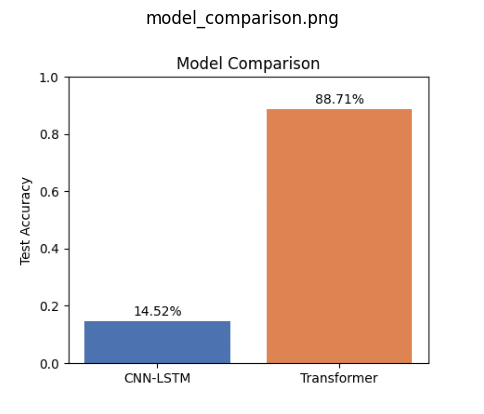

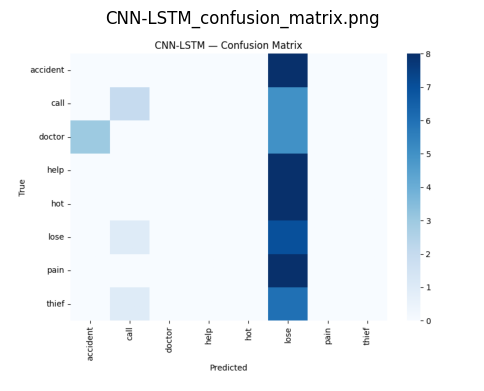

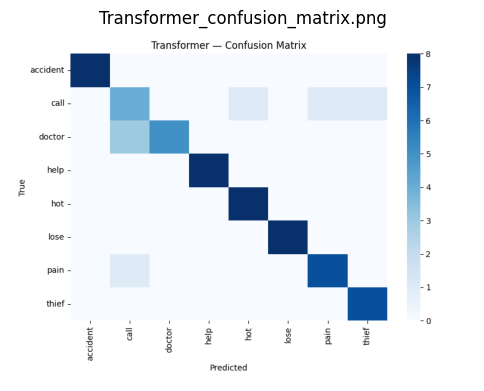

In [ ]:
# ===== Show saved comparison charts =====
for fname in ["model_comparison.png", "CNN-LSTM_confusion_matrix.png", "Transformer_confusion_matrix.png"]:
    fpath = os.path.join(TRAIN_OUTPUT_DIR, fname)
    if os.path.exists(fpath):
        img = plt.imread(fpath)
        plt.figure(figsize=(6, 5))
        plt.imshow(img)
        plt.axis("off")
        plt.title(fname)
        plt.show()


In [ ]:
# ===== Dashboard: upload a video or photo, get predictions from all 3 models =====
!pip install -q gradio mediapipe

import gradio as gr
import cv2
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

!wget -q https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task -O hand_landmarker.task

base_options = mp_python.BaseOptions(model_asset_path='hand_landmarker.task')
video_options = vision.HandLandmarkerOptions(
    base_options=base_options, running_mode=vision.RunningMode.VIDEO,
    num_hands=2, min_hand_detection_confidence=0.5,
)
image_options = vision.HandLandmarkerOptions(
    base_options=base_options, running_mode=vision.RunningMode.IMAGE,
    num_hands=2, min_hand_detection_confidence=0.5,
)

def extract_from_video_path(video_path):
    cap = cv2.VideoCapture(video_path)
    fps = cap.get(cv2.CAP_PROP_FPS) or 30
    sequence, frame_idx = [], 0
    with vision.HandLandmarker.create_from_options(video_options) as landmarker:
        while cap.isOpened():
            ret, frame = cap.read()
            if not ret:
                break
            frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame_rgb)
            timestamp_ms = int((frame_idx / fps) * 1000)
            result = landmarker.detect_for_video(mp_image, timestamp_ms)
            frame_landmarks = np.zeros(21 * 3 * 2)
            if result.hand_landmarks:
                for i, hand in enumerate(result.hand_landmarks[:2]):
                    coords = np.array([[lm.x, lm.y, lm.z] for lm in hand]).flatten()
                    frame_landmarks[i*63:(i+1)*63] = coords
            sequence.append(frame_landmarks)
            frame_idx += 1
    cap.release()
    return np.array(sequence, dtype=np.float32)

def extract_from_image_array(image_rgb):
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=image_rgb)
    with vision.HandLandmarker.create_from_options(image_options) as landmarker:
        result = landmarker.detect(mp_image)
    frame_landmarks = np.zeros(21 * 3 * 2)
    if result.hand_landmarks:
        for i, hand in enumerate(result.hand_landmarks[:2]):
            coords = np.array([[lm.x, lm.y, lm.z] for lm in hand]).flatten()
            frame_landmarks[i*63:(i+1)*63] = coords
    return np.tile(frame_landmarks, (SEQ_LEN, 1))

VIDEO_EXTS = (".mp4", ".avi", ".mov", ".mkv", ".webm", ".wmv", ".flv")
IMAGE_EXTS = (".jpg", ".jpeg", ".png", ".bmp")

def predict(uploaded_file):
    if uploaded_file is None:
        return "Upload a video or photo file first."

    file_path = uploaded_file.name  # gr.File gives a path, works for ANY format
    ext = os.path.splitext(file_path)[1].lower()

    if ext in VIDEO_EXTS:
        raw_seq = extract_from_video_path(file_path)
        note = ""
    elif ext in IMAGE_EXTS:
        image_bgr = cv2.imread(file_path)
        image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
        raw_seq = extract_from_image_array(image_rgb)
        note = "⚠️ Photo input — static images lose motion info, predictions are less reliable than video."
    else:
        return f"Unsupported file type: {ext}. Try a video (.mp4/.avi/.mov) or photo (.jpg/.png)."

    x = preprocess_one(raw_seq)[np.newaxis, ...]
    pred_cnn = cnn_lstm.predict(x, verbose=0)[0]
    pred_trans = transformer.predict(x, verbose=0)[0]
    pred_hyb = hybrid_model.predict(x, verbose=0)[0]

    result = f"""### Predictions

| Model | Prediction | Confidence |
|---|---|---|
| CNN-LSTM | **{class_names[np.argmax(pred_cnn)]}** | {pred_cnn.max():.1%} |
| Transformer | **{class_names[np.argmax(pred_trans)]}** | {pred_trans.max():.1%} |
| Hybrid CNN-Transformer | **{class_names[np.argmax(pred_hyb)]}** | {pred_hyb.max():.1%} |

{note}"""
    return result

demo = gr.Interface(
    fn=predict,
    inputs=gr.File(label="Upload a sign language video or photo (any format: mp4, avi, mov, jpg, png...)"),
    outputs=gr.Markdown(label="Prediction"),
    title="ISL Sign Language Recognition",
    description=f"Recognizes {len(class_names)} ISL words: {', '.join(class_names)}. Upload a video (preferred) or photo — any common format works.",
)

demo.launch(share=True, debug=False)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 MB 35.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.4/137.4 kB 10.4 MB/s eta 0:00:00
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://19d198b1e047997836.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
